Электроника: MAE_ср=281106, MAE_тренд=569862
Одежда: MAE_ср=241571, MAE_тренд=499191
Продукты: MAE_ср=186320, MAE_тренд=407395


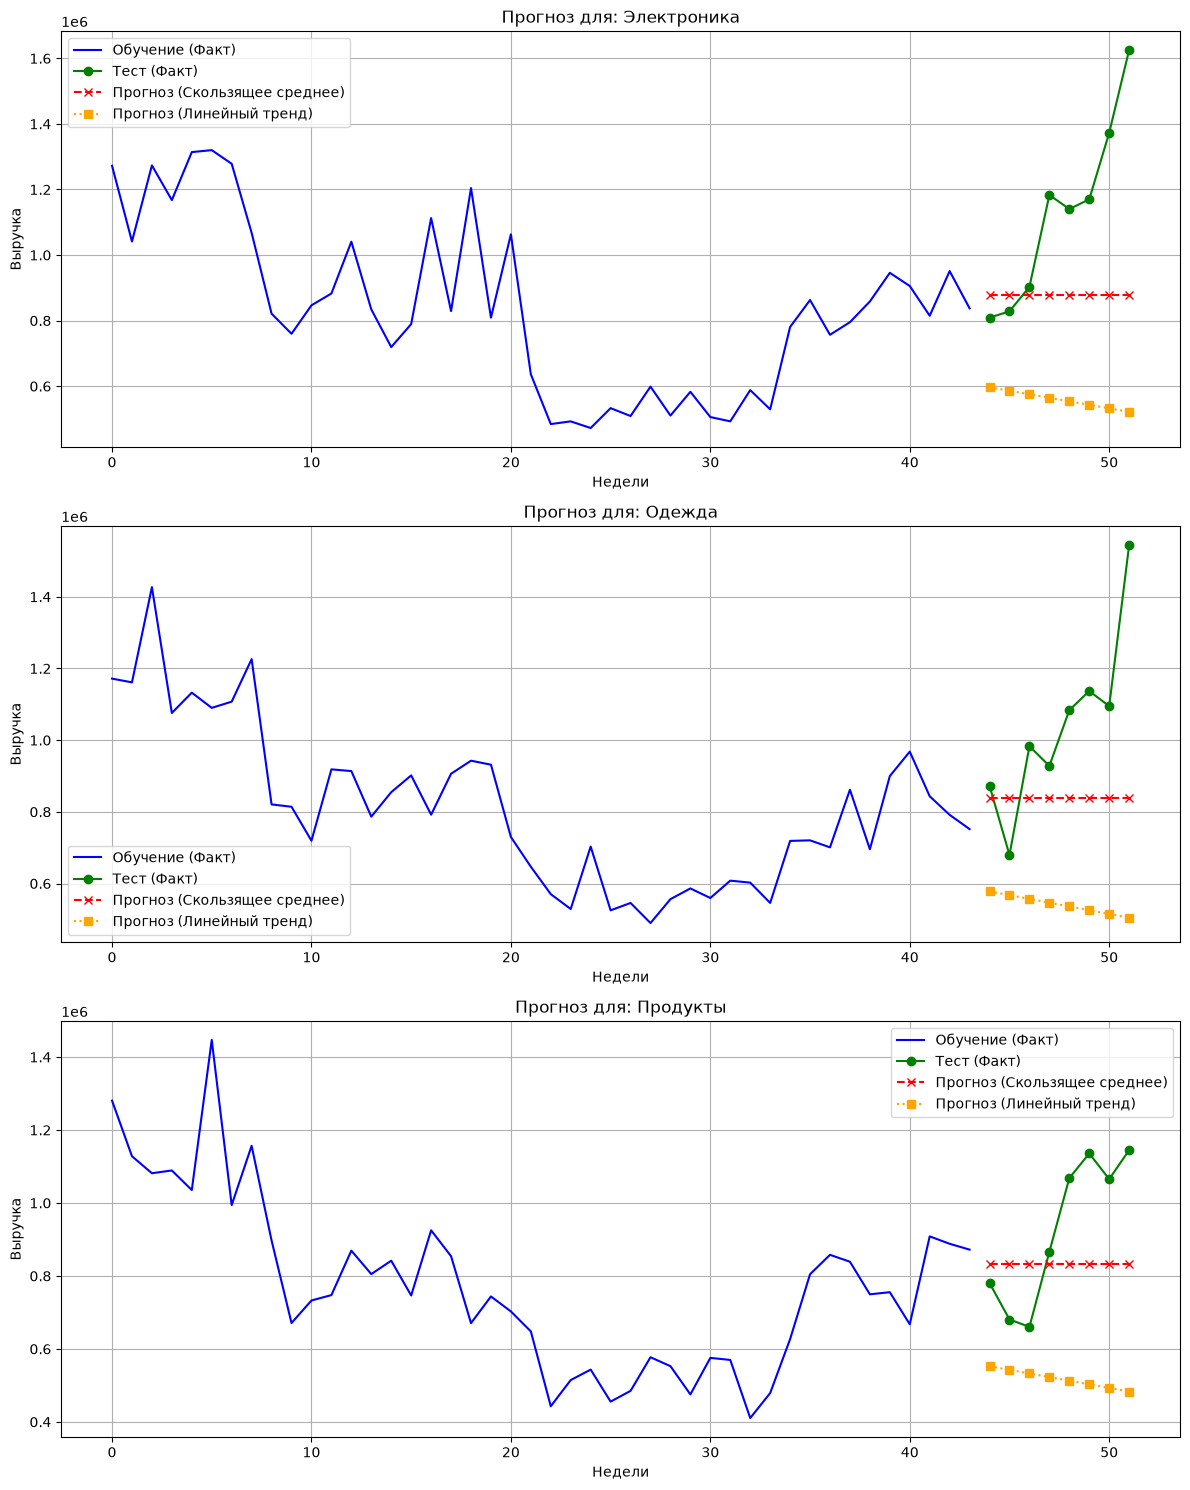

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

file_path='/Users/pashok67/Desktop/SALES_ANALYSIS/part3_synthetic_data/data/sales.csv'
df=pd.read_csv(file_path)
df['date']=pd.to_datetime(df['date'])
df['revenue']=df['qty']*df['price']

df['week']=df['date'].dt.isocalendar().week
df['year']=df['date'].dt.year
weekly_sales=df.groupby(['year', 'week', 'category'])['revenue'].sum().reset_index()

max_week=weekly_sales['week'].max()
test_weeks=range(max_week-7, max_week+1)

train=weekly_sales[weekly_sales['week'].isin(test_weeks)==False].copy()
test=weekly_sales[weekly_sales['week'].isin(test_weeks)].copy()

categories=df['category'].unique()
fig, axes=plt.subplots(len(categories), 1, figsize=(12, 15))

for i, cat in enumerate(categories):
    train_cat=train[train['category']==cat].sort_values(['year', 'week']).reset_index(drop=True)
    test_cat=test[test['category']==cat].sort_values(['year', 'week']).reset_index(drop=True)
    
    last_avg=train_cat['revenue'].rolling(window=4).mean().iloc[-1]
    forecast_rm=[last_avg]*len(test_cat)
    
    x_train=np.arange(len(train_cat))
    y_train=train_cat['revenue'].values
    coeffs=np.polyfit(x_train, y_train, deg=1)
    
    x_test=np.arange(len(train_cat), len(train_cat)+len(test_cat))
    forecast_lt=np.polyval(coeffs, x_test)
    
    ax=axes[i]
    ax.plot(train_cat.index, train_cat['revenue'], label='Обучение (Факт)', color='blue')
    ax.plot(range(len(train_cat), len(train_cat)+len(test_cat)), test_cat['revenue'], label='Тест (Факт)', color='green', marker='o')
    ax.plot(range(len(train_cat), len(train_cat)+len(test_cat)), forecast_rm, label='Прогноз (Скользящее среднее)', color='red', linestyle='--', marker='x')
    ax.plot(range(len(train_cat), len(train_cat)+len(test_cat)), forecast_lt, label='Прогноз (Линейный тренд)', color='orange', linestyle=':', marker='s')
    
    ax.set_title(f'Прогноз для: {cat}')
    ax.set_xlabel('Недели')
    ax.set_ylabel('Выручка')
    ax.legend()
    ax.grid(True)
    
    mae_rm=mean_absolute_error(test_cat['revenue'], forecast_rm)
    mae_lt=mean_absolute_error(test_cat['revenue'], forecast_lt)
    print(f"{cat}: MAE_ср={mae_rm:.0f}, MAE_тренд={mae_lt:.0f}")

plt.tight_layout()
plt.savefig('/Users/pashok67/Desktop/SALES_ANALYSIS/part4_sales_analysis/forecast_plot.png')
plt.show()